# Lab 8 – Edge Detection (Sobel, Prewitt, Canny)

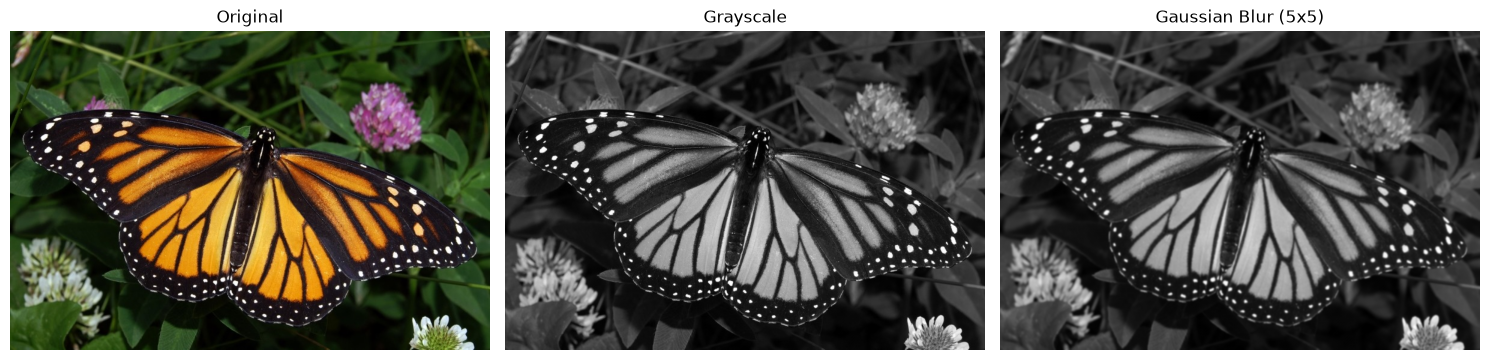

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Butterfly.jpg'  # new image (the reference notebook uses kid1.jpg)

def show_side_by_side(images, titles, cmap='gray'):
    fig, ax = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for a, im, t in zip(ax, images, titles):
        if im.ndim == 3:
            a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            a.imshow(im, cmap=cmap, vmin=0, vmax=255)
        a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)  # reduce noise before differentiation

show_side_by_side([img, gray, blurred], ['Original', 'Grayscale', 'Gaussian Blur (5x5)'])

## Task 1: Apply Edge Detection Methods

### Sobel Edge Detector

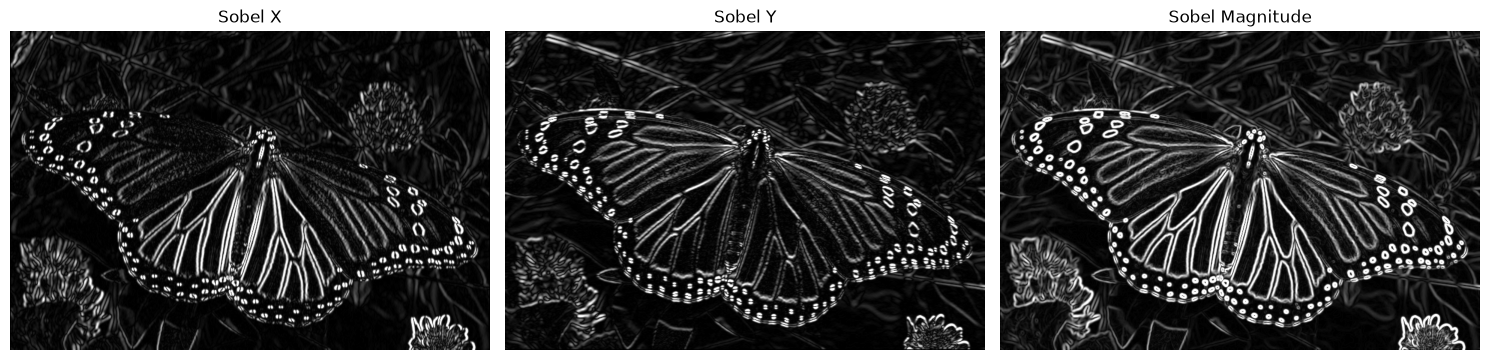

In [2]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_final = np.uint8(np.clip(cv2.magnitude(sobelx, sobely), 0, 255))

show_side_by_side([cv2.convertScaleAbs(sobelx), cv2.convertScaleAbs(sobely), sobel_final],
                  ['Sobel X', 'Sobel Y', 'Sobel Magnitude'])

### Prewitt Edge Detector

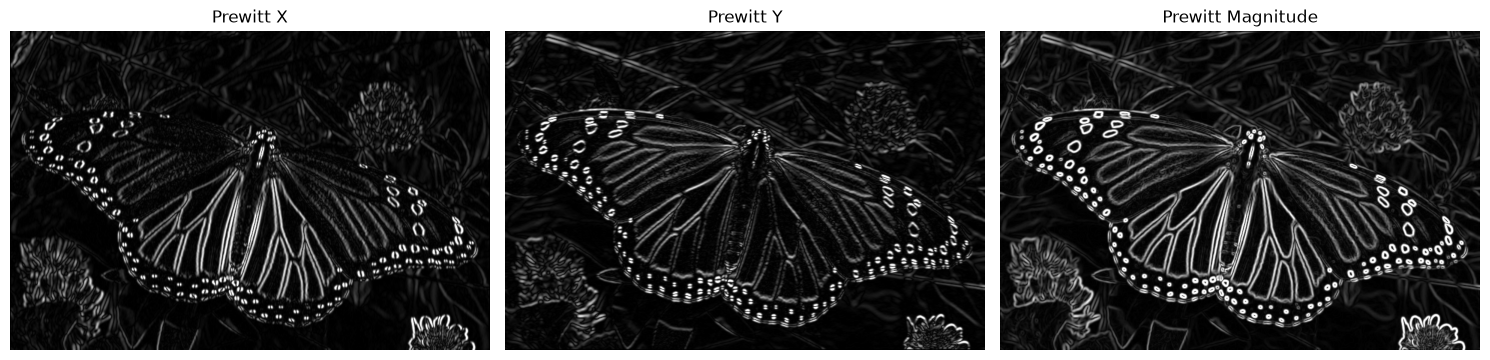

In [3]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_final = np.uint8(np.clip(cv2.magnitude(prewitt_x, prewitt_y), 0, 255))

show_side_by_side([cv2.convertScaleAbs(prewitt_x), cv2.convertScaleAbs(prewitt_y), prewitt_final],
                  ['Prewitt X', 'Prewitt Y', 'Prewitt Magnitude'])

### Canny Edge Detector

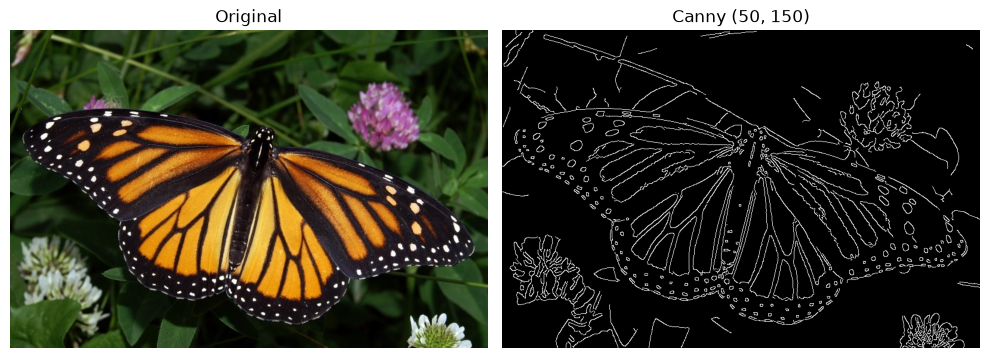

In [4]:
canny_edges = cv2.Canny(blurred, 50, 150)

show_side_by_side([img, canny_edges], ['Original', 'Canny (50, 150)'])

### Original image and the three edge maps

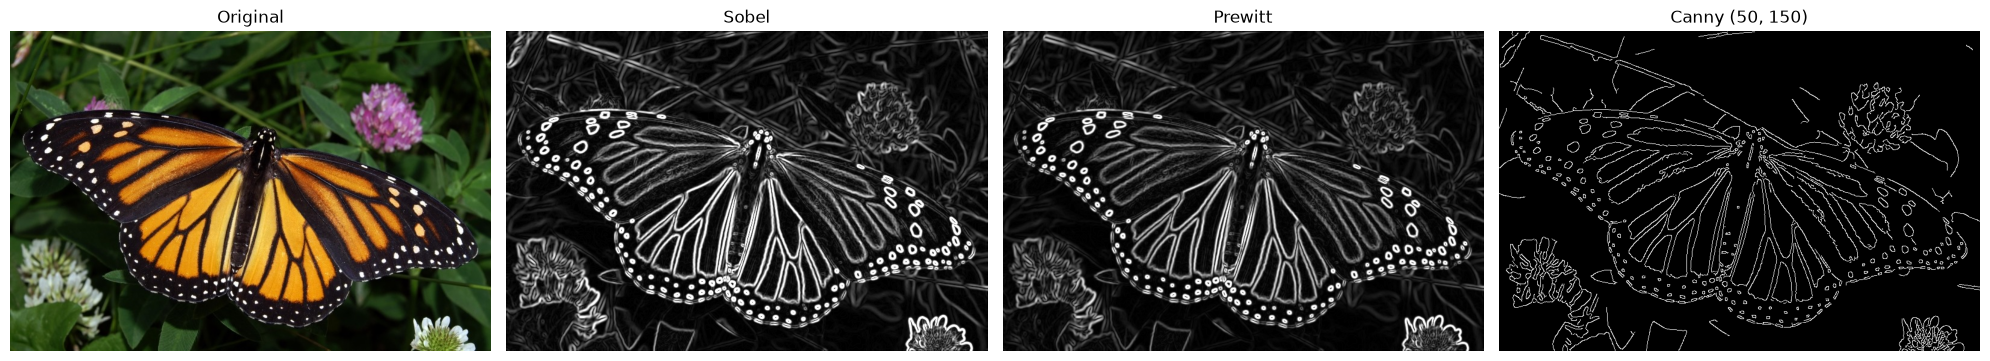

In [5]:
show_side_by_side([img, sobel_final, prewitt_final, canny_edges],
                  ['Original', 'Sobel', 'Prewitt', 'Canny (50, 150)'])

**Comparison:** Sobel and Prewitt are gradient-magnitude operators, so they give thick, grey-level edge responses whose brightness reflects edge strength; Sobel weights the centre row/column by 2, giving slightly stronger and smoother responses than Prewitt. Canny adds non-maximum suppression and hysteresis thresholding, producing thin, binary, well-connected edges of the wing veins and outline.

## Task 2: Effect of Canny Thresholds

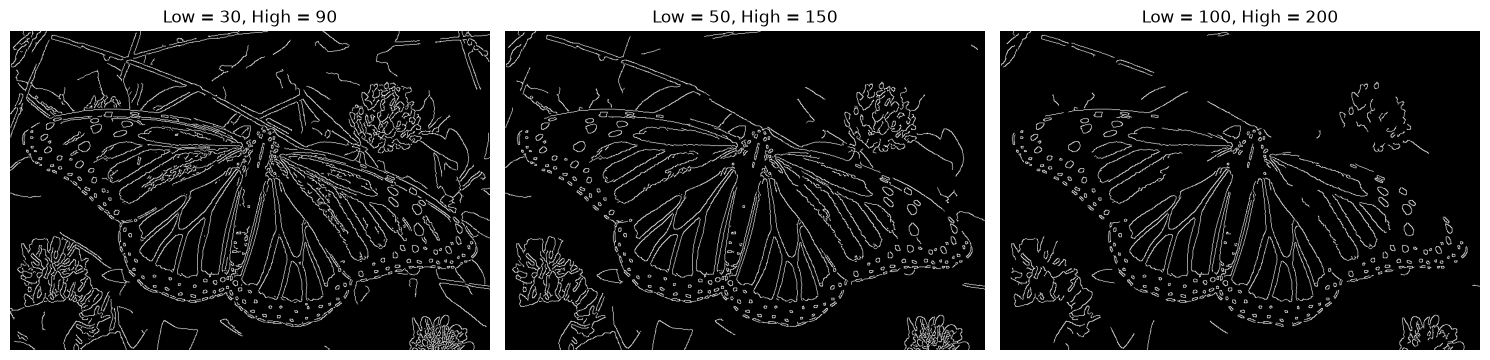

Low =  30, High =  90:  33792 edge pixels (7.94% of the image)
Low =  50, High = 150:  23434 edge pixels (5.51% of the image)
Low = 100, High = 200:  16823 edge pixels (3.95% of the image)


In [6]:
thresholds = [(30, 90), (50, 150), (100, 200)]
canny_maps = [cv2.Canny(blurred, lo, hi) for lo, hi in thresholds]

show_side_by_side(canny_maps, [f'Low = {lo}, High = {hi}' for lo, hi in thresholds])
for (lo, hi), e in zip(thresholds, canny_maps):
    print(f'Low = {lo:>3}, High = {hi:>3}: {np.count_nonzero(e):>6} edge pixels '
          f'({100 * np.count_nonzero(e) / e.size:.2f}% of the image)')

**Explanation:** In Canny, pixels with gradient above **High** are strong edges, pixels below **Low** are discarded, and pixels in between are kept only if they connect to a strong edge (hysteresis).

- **Low = 30, High = 90:** the lowest thresholds keep the most edges. Fine details such as the small wing patterns and texture are visible, but background texture and noise also appear as spurious edges.
- **Low = 50, High = 150:** a balanced result. The main wing structure and veins remain while much of the weak texture/noise is removed.
- **Low = 100, High = 200:** the highest thresholds keep only the strongest edges. The output is cleanest, with mainly the outline and dominant boundaries, but fine details are lost and some contours become broken.

So increasing the thresholds **decreases the number of detected edges** (as the pixel counts above show) and reduces noise, at the cost of losing weak edges and fine image details; decreasing them does the opposite.